# Entregable 5 – Estudio de Valores Atípicos (Outliers)

**Asignatura:** Procesamiento de datos  
**Autora:** Taisiia Bogatyreva

## Objetivo
1. Generar un set de datos sintéticos con outliers conocidos.
2. Estudiar los outliers con todos los métodos vistos en clase: boxplot, IQR, Z-score, tratamiento (eliminación, transformación logarítmica, winsorización) y detección multivariante (Isolation Forest, DBSCAN).
3. Documentar las decisiones tomadas.

In [41]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.ensemble import IsolationForest
from sklearn.cluster import DBSCAN
from sklearn.preprocessing import StandardScaler

np.random.seed(42)   # reproducibilidad

## 1. Generación de datos sintéticos

Simularemos un mini-dataset de **departamentos** con tres variables:
- `superficie_m2` (distribución normal),
- `precio` (relacionado con la superficie, con ruido),
- `antiguedad` (años).

Luego **insertaremos a mano** outliers de dos tipos:
- *univariantes extremos* (un precio absurdamente alto),
- *multivariantes* (superficie muy chica con precio muy alto: combinación inusual).

> **Tu tarea:** completa la celda siguiente.  
> *Pista:* `np.random.normal(loc=..., scale=..., size=...)` para la superficie; el precio puede ser `superficie * valor_por_m2 + ruido`. Crea un `DataFrame` con `pd.DataFrame({...})`.

In [42]:
# TODO: generar df con ~300 filas normales
n = 300   # сколько нормальных квартир генерируем

# Площадь: нормальное распределение, среднее 70 м², разброс (σ) 15 м²
superficie = np.random.normal(loc=70, scale=15, size=n)
superficie = np.clip(superficie, 25, None)   # меньше 25 м² не бывает

# Цена зависит от площади: 2000 за м² + случайный шум
precio = superficie * 2000 + np.random.normal(loc=0, scale=10000, size=n)

# Возраст здания: целые числа от 0 до 50
antiguedad = np.random.randint(0, 51, size=n)

df_normal = pd.DataFrame({
    'superficie_m2': superficie.round(1),
    'precio': precio.round(0),
    'antiguedad': antiguedad
})
df_normal['es_outlier_real'] = 0   # 0 = обычная квартира

df_normal.head()

,superficie_m2,precio,antiguedad,es_outlier_real
0,77.5,146611.0,46,0
1,67.9,130250.0,3,0
2,79.7,166904.0,11,0
3,92.8,191795.0,44,0
4,66.5,132766.0,1,0


> **Tu tarea:** agrega ~10 outliers a mano.  
> *Pista:* crea un segundo `DataFrame` con los valores extremos y únelos con `pd.concat([...], ignore_index=True)`. Guarda una columna `es_outlier_real` (0/1) para poder comprobar después qué métodos los encuentran.

In [43]:
# TODO: insertar outliers conocidos
# Одномерные выбросы: нормальная площадь, но абсурдная цена
df_uni = pd.DataFrame({
    'superficie_m2': [60, 75, 85, 70],
    'precio': [1_500_000, 1_200_000, 2_000_000, 950_000],
    'antiguedad': [10, 25, 5, 40]
})
df_uni['es_outlier_real'] = 1

# Многомерные выбросы: маленькая площадь и высокая цена
df_multi = pd.DataFrame({
    'superficie_m2': [33, 35, 37, 39, 41, 36],
    'precio': [185_000, 195_000, 175_000, 200_000, 190_000, 180_000],
    'antiguedad': [12, 30, 8, 45, 20, 3]
})
df_multi['es_outlier_real'] = 1

> Revisa el resultado con `df.head()`, `df.describe()` y `df['es_outlier_real'].value_counts()`.

In [44]:
# TODO: inspección inicial
df = pd.concat([df_normal, df_uni, df_multi], ignore_index=True)

# Перемешиваем строки, чтобы выбросы не лежали в конце
df = df.sample(frac=1, random_state=42).reset_index(drop=True)

print(df.shape)
print(df['es_outlier_real'].value_counts())
df.describe().round(0)

(310, 4)
es_outlier_real
0    300
1     10
Name: count, dtype: int64


,superficie_m2,precio,antiguedad,es_outlier_real
count,310.0,310.0,310.0,310.0
mean,69.0,156993.0,26.0,0.0
std,15.0,153636.0,15.0,0.0
min,25.0,58711.0,0.0,0.0
25%,59.0,120828.0,13.0,0.0
50%,70.0,141134.0,26.0,0.0
75%,79.0,160443.0,39.0,0.0
max,128.0,2000000.0,50.0,1.0


## 2. Detección univariante

### 2.1 Boxplot
> **Tu tarea:** dibuja un boxplot de `precio` y otro de `superficie_m2`.  
> *Pista:* `sns.boxplot(x=df['precio'])`.

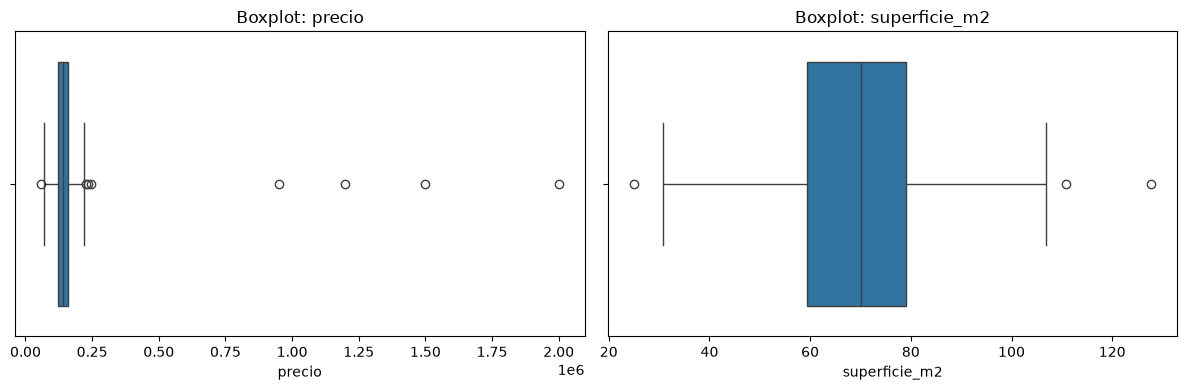

In [45]:
# TODO: boxplots
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.boxplot(x=df['precio'], ax=axes[0])
axes[0].set_title('Boxplot: precio')

sns.boxplot(x=df['superficie_m2'], ax=axes[1])
axes[1].set_title('Boxplot: superficie_m2')

plt.tight_layout()
plt.show()

### 2.2 Método IQR
> **Tu tarea:** calcula `Q1`, `Q3`, `IQR`, los límites inferior y superior para `precio` y cuenta los outliers.  
> *Pista:* `df['precio'].quantile(0.25)`. Los outliers son los valores **fuera** de `[lim_inf, lim_sup]`.  
> Conviene escribir una función `detectar_iqr(serie, k=1.5)` que devuelva una máscara booleana, para reutilizarla.

In [46]:
# TODO: función detectar_iqr y aplicación
def detectar_iqr(serie, k=1.5):
    q1 = serie.quantile(0.25)
    q3 = serie.quantile(0.75)
    iqr = q3 - q1
    lim_inf = q1 - k * iqr
    lim_sup = q3 + k * iqr
    mascara = (serie < lim_inf) | (serie > lim_sup)
    return mascara, lim_inf, lim_sup


mascara_precio, lim_inf, lim_sup = detectar_iqr(df['precio'])

print(f"Límite inferior: {lim_inf:,.0f}")
print(f"Límite superior: {lim_sup:,.0f}")
print("Outliers IQR en precio:", mascara_precio.sum())

# Сколько из найденных на самом деле подложенные?
print(df.loc[mascara_precio, 'es_outlier_real'].value_counts())

# Сами строки, от дорогих к дешёвым
df[mascara_precio].sort_values('precio', ascending=False)

Límite inferior: 61,406
Límite superior: 219,864
Outliers IQR en precio: 8
es_outlier_real
0    4
1    4
Name: count, dtype: int64


,superficie_m2,precio,antiguedad,es_outlier_real
56,85.0,2000000.0,5,1
223,60.0,1500000.0,10,1
245,75.0,1200000.0,25,1
187,70.0,950000.0,40,1
165,127.8,247272.0,1,0
42,110.8,232801.0,46,0
26,106.9,226674.0,21,0
75,25.0,58711.0,17,0


### 2.3 Método Z-score
> **Tu tarea:** calcula el Z-score de `precio` y marca como outliers los que cumplen `|Z| > 3`.  
> *Pista:* `stats.zscore(...)` y `np.abs(...)`.  
> Luego **compara** cuántos outliers detecta IQR vs. Z-score. ¿Coinciden? ¿Por qué podrían diferir? (recuerda el efecto de *masking*).

In [47]:
# TODO: función detectar_zscore, comparación con IQR
def detectar_zscore(serie, umbral=3):
    z = stats.zscore(serie)
    mascara = np.abs(z) > umbral
    return mascara, z


mascara_z, z_precio = detectar_zscore(df['precio'])

print("Outliers Z-score en precio:", mascara_z.sum())
print(df.loc[mascara_z, 'es_outlier_real'].value_counts())

# Таблица: у скольких подложенных выбросов какой Z?
tabla_z = df[['superficie_m2', 'precio', 'es_outlier_real']].copy()
tabla_z['z_precio'] = z_precio.round(2)
tabla_z[tabla_z['es_outlier_real'] == 1].sort_values('precio', ascending=False)

Outliers Z-score en precio: 4
es_outlier_real
1    4
Name: count, dtype: int64


,superficie_m2,precio,es_outlier_real,z_precio
56,85.0,2000000.0,1,12.02
223,60.0,1500000.0,1,8.76
245,75.0,1200000.0,1,6.80
187,70.0,950000.0,1,5.17
13,39.0,200000.0,1,0.28
127,35.0,195000.0,1,0.25
283,41.0,190000.0,1,0.22
275,33.0,185000.0,1,0.18
303,36.0,180000.0,1,0.15
206,37.0,175000.0,1,0.12


### 2.4. IQR vs Z-score

In [48]:

print("IQR:     ", mascara_precio.sum())
print("Z-score: ", mascara_z.sum())
print("Оба:     ", (mascara_precio & mascara_z).sum())
print("Только IQR:", (mascara_precio & ~mascara_z).sum())

IQR:      8
Z-score:  4
Оба:      4
Только IQR: 4


### 2.5. Efecto de enmascaramiento (masking)

In [49]:
sin_extremos = df[df['precio'] < 900_000]['precio']

print("С выбросами:  среднее", round(df['precio'].mean()), " σ", round(df['precio'].std()))
print("Без выбросов: среднее", round(sin_extremos.mean()), " σ", round(sin_extremos.std()))

# Те же «спорные» строки, которые нашёл только IQR: какой у них Z?
solo_iqr = mascara_precio & ~mascara_z
z_antes = z_precio[solo_iqr.values]
z_despues = (df.loc[solo_iqr, 'precio'] - sin_extremos.mean()) / sin_extremos.std()

print("Z с выбросами в данных:  ", z_antes.round(2))
print("Z без экстремальных цен: ", z_despues.round(2).values)

С выбросами:  среднее 156993  σ 153636
Без выбросов: среднее 140581  σ 31054
Z с выбросами в данных:   [ 0.45  0.49 -0.64  0.59]
Z без экстремальных цен:  [ 2.77  2.97 -2.64  3.44]


## 3. Tratamiento de outliers

### 3.1 Eliminación
> **Tu tarea:** crea `df_sin_outliers` filtrando los outliers detectados por IQR en `precio`. Compara `media` y `std` antes/después.  
> Recuerda la regla de oro: *documentar por qué se elimina*.

In [50]:
# TODO: eliminación y comparación de estadísticas
# Оставляем только строки, которые НЕ выбросы (~ означает «не»)
df_sin_outliers = df[~mascara_precio].copy()

print("Строк до:", len(df), " после:", len(df_sin_outliers))
print("Удалено:", mascara_precio.sum())

# Сравнение статистик до и после
comparacion = pd.DataFrame({
    'antes': df['precio'].agg(['mean', 'median', 'std', 'min', 'max']),
    'después': df_sin_outliers['precio'].agg(['mean', 'median', 'std', 'min', 'max'])
}).round(0)
comparacion

Строк до: 310  после: 302
Удалено: 8


,antes,después
mean,156993.0,139909.0
median,141134.0,140311.0
std,153636.0,29389.0
min,58711.0,70642.0
max,2000000.0,219400.0


In [51]:
# Журнал: что именно мы удалили и были ли они настоящими выбросами
eliminados = df[mascara_precio]
print(eliminados['es_outlier_real'].value_counts())
print("Настоящих выбросов осталось в данных:", df_sin_outliers['es_outlier_real'].sum())
eliminados[['superficie_m2', 'precio', 'es_outlier_real']]

es_outlier_real
0    4
1    4
Name: count, dtype: int64
Настоящих выбросов осталось в данных: 6


,superficie_m2,precio,es_outlier_real
26,106.9,226674.0,0
42,110.8,232801.0,0
56,85.0,2000000.0,1
75,25.0,58711.0,0
165,127.8,247272.0,0
187,70.0,950000.0,1
223,60.0,1500000.0,1
245,75.0,1200000.0,1


### 3.2 Transformación logarítmica
> **Tu tarea:** crea `precio_log = np.log1p(df['precio'])` y compara los histogramas de `precio` y `precio_log` (`sns.histplot`).

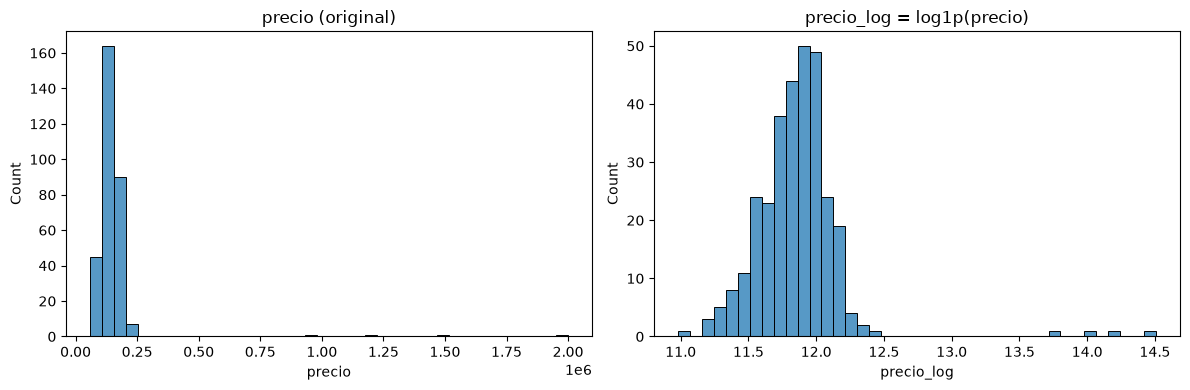

Асимметрия (skew) precio:     9.25
Асимметрия (skew) precio_log: 3.51


In [52]:
# TODO: transformación log + histogramas
df['precio_log'] = np.log1p(df['precio'])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(df['precio'], bins=40, ax=axes[0])
axes[0].set_title('precio (original)')

sns.histplot(df['precio_log'], bins=40, ax=axes[1])
axes[1].set_title('precio_log = log1p(precio)')

plt.tight_layout()
plt.show()

print("Асимметрия (skew) precio:    ", round(df['precio'].skew(), 2))
print("Асимметрия (skew) precio_log:", round(df['precio_log'].skew(), 2))

### 3.3 Winsorización
> **Tu tarea:** calcula los percentiles 1 y 99 de `precio` y recorta con `np.clip(...)`. Guarda el resultado en `precio_winsor`.  
> Compara los boxplots de `precio` y `precio_winsor`.

In [53]:
# TODO: winsorización
p1 = df['precio'].quantile(0.01)
p99 = df['precio'].quantile(0.99)
print(f"p1 = {p1:,.0f}   p99 = {p99:,.0f}")

df['precio_winsor'] = np.clip(df['precio'], p1, p99)

print("Изменено значений:", (df['precio'] != df['precio_winsor']).sum())

# Статистики до и после
df[['precio', 'precio_winsor']].agg(['mean', 'median', 'std', 'min', 'max']).round(0)

p1 = 72,804   p99 = 886,754
Изменено значений: 8


,precio,precio_winsor
mean,156993.0,150269.0
median,141134.0,141134.0
std,153636.0,89757.0
min,58711.0,72804.0
max,2000000.0,886754.0


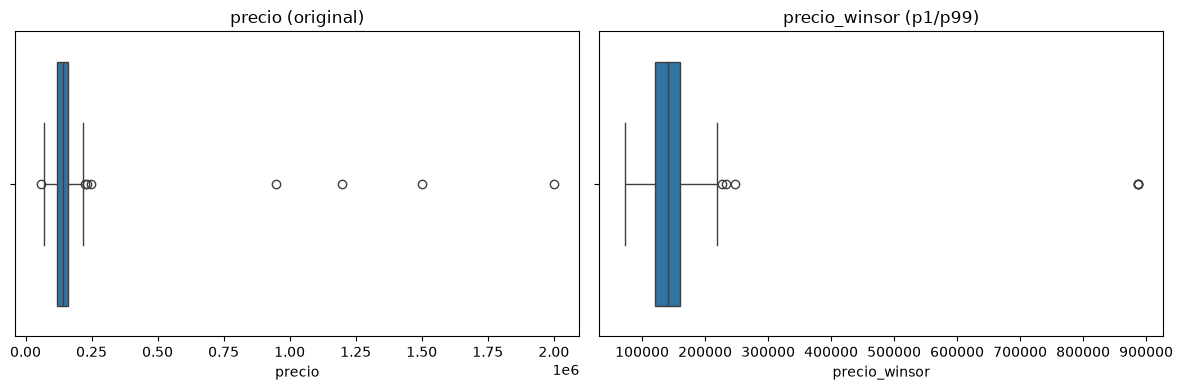

In [54]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.boxplot(x=df['precio'], ax=axes[0])
axes[0].set_title('precio (original)')

sns.boxplot(x=df['precio_winsor'], ax=axes[1])
axes[1].set_title('precio_winsor (p1/p99)')

plt.tight_layout()
plt.show()

### 3.3 Winsorización IQR (mejor)

In [55]:
_, lim_inf, lim_sup = detectar_iqr(df['precio'])
print(f"Границы IQR: {lim_inf:,.0f} ... {lim_sup:,.0f}")

df['precio_winsor_iqr'] = np.clip(df['precio'], lim_inf, lim_sup)

print("Изменено значений:", (df['precio'] != df['precio_winsor_iqr']).sum())

df[['precio', 'precio_winsor', 'precio_winsor_iqr']].agg(
    ['mean', 'median', 'std', 'min', 'max']
).round(0)

Границы IQR: 61,406 ... 219,864
Изменено значений: 8


,precio,precio_winsor,precio_winsor_iqr
mean,156993.0,150269.0,141461.0
median,141134.0,141134.0,141134.0
std,153636.0,89757.0,31681.0
min,58711.0,72804.0,61406.0
max,2000000.0,886754.0,219864.0


## 4. Detección multivariante

### 4.1 Scatterplot
> **Tu tarea:** dibuja `superficie_m2` (x) vs `precio` (y). Colorea los puntos según `es_outlier_real` (`hue=`). ¿Se ven los outliers multivariantes?

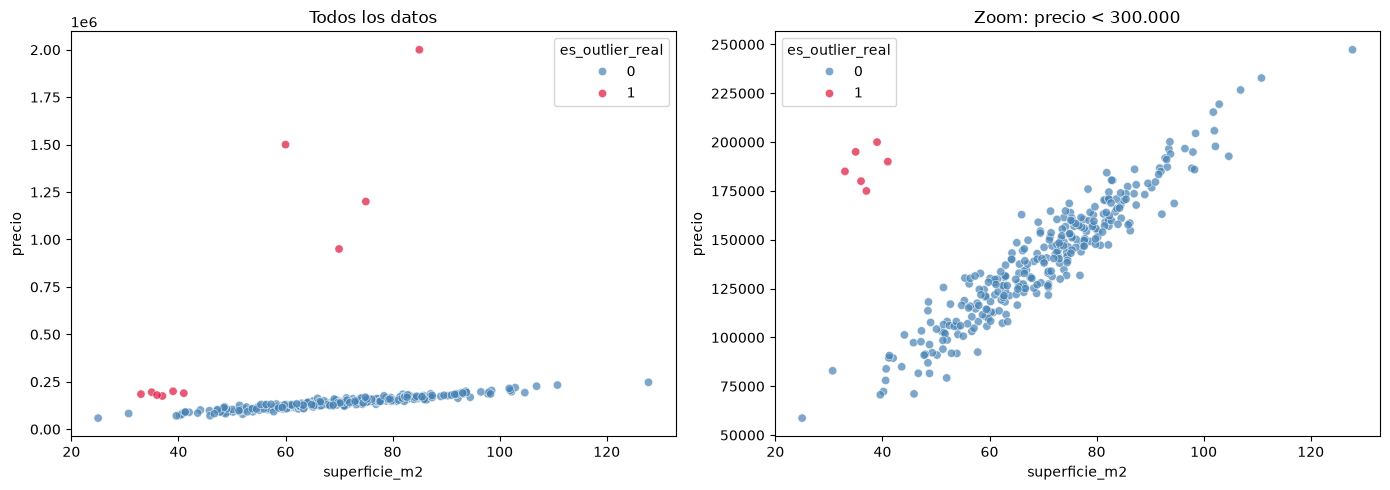

In [56]:
# TODO: scatterplot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Слева: все данные
sns.scatterplot(data=df, x='superficie_m2', y='precio', hue='es_outlier_real',
                palette={0: 'steelblue', 1: 'crimson'}, alpha=0.7, ax=axes[0])
axes[0].set_title('Todos los datos')

# Справа: приближение, без четырёх гигантских цен
zoom = df[df['precio'] < 300_000]
sns.scatterplot(data=zoom, x='superficie_m2', y='precio', hue='es_outlier_real',
                palette={0: 'steelblue', 1: 'crimson'}, alpha=0.7, ax=axes[1])
axes[1].set_title('Zoom: precio < 300.000')

plt.tight_layout()
plt.show()

### 4.2 Isolation Forest
> **Tu tarea:** entrena `IsolationForest(contamination=..., random_state=42)` sobre `['superficie_m2', 'precio']`.  
> *Pista:* `fit_predict(...)` devuelve `-1` para anomalías y `1` para puntos normales. Guarda el resultado en `df['iso_forest']` y grafica.

In [57]:
# TODO: Isolation Forest
X = df[['superficie_m2', 'precio']]

iso = IsolationForest(n_estimators=100, contamination=0.05, random_state=42)
df['iso_forest'] = iso.fit_predict(X)    # -1 = аномалия, 1 = норма

print(df['iso_forest'].value_counts())
pd.crosstab(df['es_outlier_real'], df['iso_forest'])

iso_forest
 1    294
-1     16
Name: count, dtype: int64


iso_forest,-1,1
es_outlier_real,,
0,6,294
1,10,0


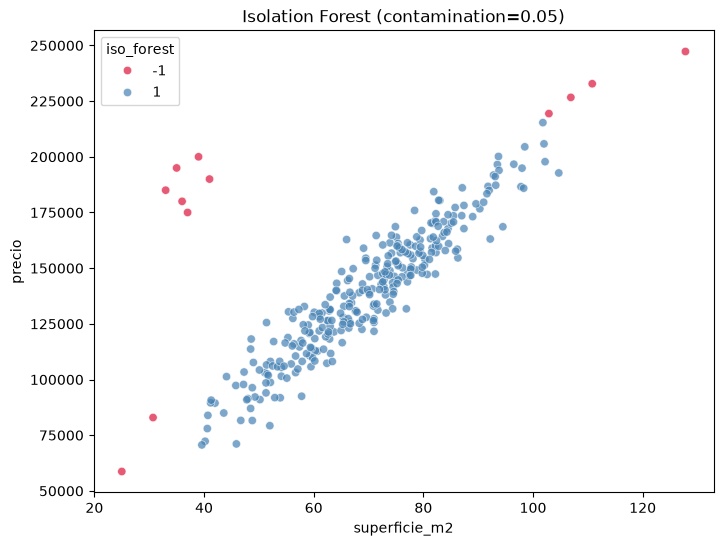

In [58]:
zoom = df[df['precio'] < 300_000]

plt.figure(figsize=(8, 6))
sns.scatterplot(data=zoom, x='superficie_m2', y='precio', hue='iso_forest',
                palette={1: 'steelblue', -1: 'crimson'}, alpha=0.7)
plt.title('Isolation Forest (contamination=0.05)')
plt.show()

### 4.3 DBSCAN
> **Tu tarea:** DBSCAN usa distancias, así que **primero escala** los datos con `StandardScaler`.  
> Luego `DBSCAN(eps=..., min_samples=...)`; las etiquetas `-1` son ruido (anomalías). Prueba 2–3 valores de `eps` y observa cómo cambia el resultado.

In [59]:
# TODO: escalado + DBSCAN
resultados = []

for cont in [0.02, 0.03, 0.05, 0.08, 0.10]:
    iso = IsolationForest(n_estimators=100, contamination=cont, random_state=42)
    etiquetas = iso.fit_predict(X)
    marcados = etiquetas == -1
    resultados.append({
        'contamination': cont,
        'marcados': marcados.sum(),
        'reales_encontrados': (marcados & (df['es_outlier_real'] == 1)).sum(),
        'falsos_positivos': (marcados & (df['es_outlier_real'] == 0)).sum()
    })

pd.DataFrame(resultados)

,contamination,marcados,reales_encontrados,falsos_positivos
0,0.02,7,4,3
1,0.03,10,6,4
2,0.05,16,10,6
3,0.08,25,10,15
4,0.10,31,10,21


### 4.4. Escalado y selección de EPS

In [60]:
# DBSCAN работает с расстояниями, поэтому сначала приводим признаки к одному масштабу
X_scaled = StandardScaler().fit_transform(df[['superficie_m2', 'precio']])

resultados_db = []

for eps in [0.1, 0.15, 0.2, 0.25, 0.3, 0.5]:
    etiquetas = DBSCAN(eps=eps, min_samples=5).fit_predict(X_scaled)
    ruido = etiquetas == -1
    resultados_db.append({
        'eps': eps,
        'ruido': ruido.sum(),
        'reales_encontrados': (ruido & (df['es_outlier_real'] == 1)).sum(),
        'falsos_positivos': (ruido & (df['es_outlier_real'] == 0)).sum(),
        'clusters': len(set(etiquetas)) - (1 if -1 in etiquetas else 0)
    })

pd.DataFrame(resultados_db)

,eps,ruido,reales_encontrados,falsos_positivos,clusters
0,0.10,28,10,18,4
1,0.15,20,10,10,3
2,0.20,15,10,5,2
3,0.25,10,5,5,2
4,0.30,8,4,4,2
5,0.50,7,4,3,2


### 4.5. DBSCAN final y gráfico

dbscan_anomalia  False  True 
es_outlier_real              
0                  295      5
1                    0     10


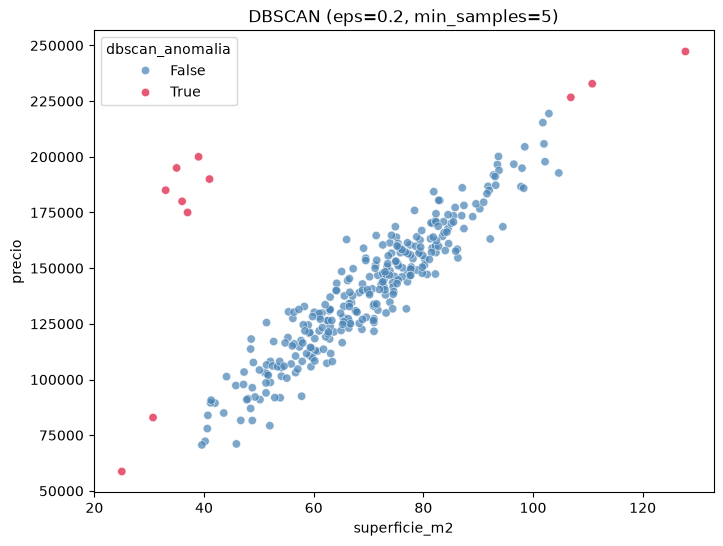

In [61]:
df['dbscan'] = DBSCAN(eps=0.2, min_samples=5).fit_predict(X_scaled)
df['dbscan_anomalia'] = df['dbscan'] == -1

print(pd.crosstab(df['es_outlier_real'], df['dbscan_anomalia']))

zoom = df[df['precio'] < 300_000]

plt.figure(figsize=(8, 6))
sns.scatterplot(data=zoom, x='superficie_m2', y='precio', hue='dbscan_anomalia',
                palette={False: 'steelblue', True: 'crimson'}, alpha=0.7)
plt.title('DBSCAN (eps=0.2, min_samples=5)')
plt.show()

## 5. Comparación de métodos
> **Tu tarea:** arma una tabla resumen: para cada método (IQR, Z-score, Isolation Forest, DBSCAN) cuántos outliers reales detectó (usa `es_outlier_real`) y cuántos falsos positivos tuvo.

In [62]:
# Тип настоящего выброса (для таблицы): по цене отличаем два вида подложенных
df['tipo'] = np.where(df['es_outlier_real'] == 0, 'normal',
                      np.where(df['precio'] >= 900_000, 'univariante', 'multivariante'))


def evaluar(mascara, nombre):
    mascara = pd.Series(np.asarray(mascara), index=df.index)
    real = df['es_outlier_real'] == 1
    tp = (mascara & real).sum()      # найденные настоящие выбросы
    fp = (mascara & ~real).sum()     # ложные срабатывания
    return {
        'método': nombre,
        'marcados': mascara.sum(),
        'univ. (de 4)': (mascara & (df['tipo'] == 'univariante')).sum(),
        'multiv. (de 6)': (mascara & (df['tipo'] == 'multivariante')).sum(),
        'falsos positivos': fp,
        'recall': round(tp / real.sum(), 2),
        'precision': round(tp / mascara.sum(), 2) if mascara.sum() > 0 else 0
    }


tabla = pd.DataFrame([
    evaluar(mascara_precio, 'IQR (precio)'),
    evaluar(mascara_z, 'Z-score (precio)'),
    evaluar(df['iso_forest'] == -1, 'Isolation Forest'),
    evaluar(df['dbscan_anomalia'], 'DBSCAN'),
])
tabla

,método,marcados,univ. (de 4),multiv. (de 6),falsos positivos,recall,precision
0,IQR (precio),8,4,0,4,0.4,0.50
1,Z-score (precio),4,4,0,0,0.4,1.00
2,Isolation Forest,16,4,6,6,1.0,0.62
3,DBSCAN,15,4,6,5,1.0,0.67


## 6. Conclusiones y decisiones documentadas
Responde brevemente:
1. ¿Qué método detectó mejor los outliers univariantes? ¿Y los multivariantes?
2. ¿Qué tratamiento aplicarías a cada tipo de outlier y por qué?
3. ¿Qué riesgos tendría eliminar estos datos en un caso real?

*(escribe aquí tus conclusiones)*

### 6.1 ¿Qué método detectó mejor cada tipo de outlier?

**Outliers univariantes** (4 precios entre 950.000 y 2.000.000): IQR y Z-score los
detectaron todos. El Z-score no tuvo falsos positivos (precision = 1.00), mientras que
el IQR marcó además 1 registro legítimo (precision = 0.80). Sin embargo, el Z-score es
sensible al *masking*: los 4 valores extremos inflaron la desviación estándar de
≈30.000 a ≈153.000, y un registro con Z = 0.43 pasó a Z = 2.76 al calcularlo sin ellos.
El IQR, basado en cuartiles, resultó más robusto.

**Outliers multivariantes** (superficie 33–41 m² con precio 175.000–200.000): IQR y
Z-score no detectaron ninguno (0 de 6), porque cada variable por separado tiene valores
normales. Isolation Forest y DBSCAN detectaron los 6 (recall = 1.0), a costa de
6 y 8 falsos positivos respectivamente (precision 0.62 y 0.56).
En nuestro caso Isolation Forest fue algo más preciso y menos sensible a sus parámetros:
DBSCAN pasó de encontrar 10 de 10 (eps = 0.20) a 5 de 10 (eps = 0.25).

### 6.2 ¿Qué tratamiento aplicaría a cada tipo de outlier?

- **Univariantes (precios absurdos):** un departamento de 85 m² a 2.000.000 es
  inverosímil frente al resto, por lo que, previa verificación de que es un error de
  carga, se eliminarían o corregirían. Si no se puede confirmar, la winsorización con los
  límites del IQR conserva los 310 registros y reduce la desviación estándar de ≈153.000
  a ≈31.000. La winsorización con p1/p99 resultó poco eficaz (p99 = 885.046), porque los
  outliers superan el 1 % de los datos y contaminan el propio percentil.
  La transformación logarítmica reduce la asimetría, pero no elimina los outliers.
- **Multivariantes:** no los eliminaría automáticamente. Primero revisaría cada caso
  (¿un departamento pequeño pero céntrico o de lujo?, ¿error de carga de la superficie?).
  Si son legítimos, los conservaría y usaría modelos robustos o una variable indicadora.

### 6.3 Riesgos de eliminar estos datos en un caso real

- Podría eliminarse información valiosa: un valor extremo legítimo (como un fraude
  real) es justamente el patrón que se quiere detectar.
- Los falsos positivos son datos legítimos: DBSCAN marcó 8 departamentos normales muy
  pequeños o muy grandes; eliminarlos sesgaría el modelo hacia los casos "promedio".
- Los resultados dependen de parámetros elegidos (contamination, eps, umbral de Z), y
  sin una etiqueta real como `es_outlier_real` no se puede validar la elección.
- Regla de oro: toda eliminación debe documentarse (qué, cuántos y por qué).